# 2.1 Basis of design: materials, actions, durability, fire

What every design starts with: limit states, partial factors, material strengths, load combinations, cover and fire.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

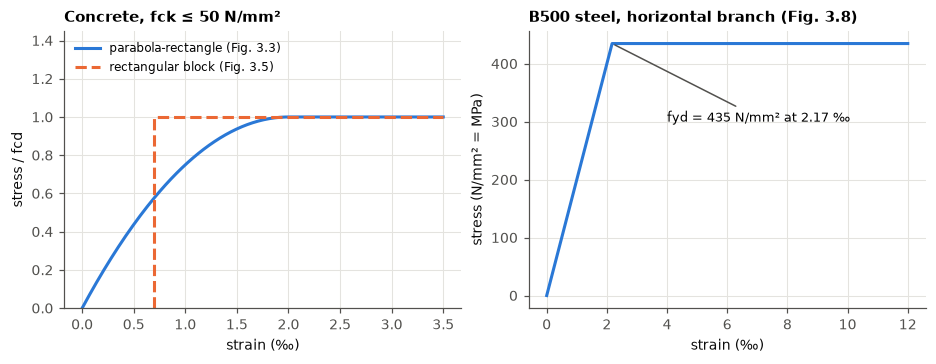

In [2]:
P.stress_strain()

## Limit state principle (EN 1990)

$$E_d \le R_d \quad\text{(ultimate limit state)}, \qquad E_d \le C_d \quad\text{(serviceability limit state)}$$

| Combination | Expression | Use |
|:--|:--|:--|
| ULS, persistent | $1.35G_k + 1.5Q_k$ (Exp. 6.10) | Strength. Exp. (6.10a)/(6.10b) may be used instead; this guide uses (6.10) throughout |
| SLS characteristic | $G_k + Q_k$ (Exp. 6.14b) | Bearing pressure, irreversible effects |
| SLS quasi-permanent | $G_k + \psi_2 Q_k$ (Exp. 6.16b) | Cracking, long-term deflection |

| Category (EN 1990 Table A1.1) | ψ₀ | ψ₁ | ψ₂ |
|:--|:-:|:-:|:-:|
| A domestic, B offices | 0.7 | 0.5 | 0.3 |
| C congregation, D shopping | 0.7 | 0.7 | 0.6 |
| E storage | 1.0 | 0.9 | 0.8 |

## Assumptions for section design (EC2 6.1(2)P)

1. Plane sections remain plane.
2. Bonded reinforcement has the same strain as the surrounding concrete.
3. The tensile strength of concrete is ignored.
4. Concrete stress follows EC2 3.1.7; steel stress follows EC2 3.2.7.
5. Concrete strain is limited to ε<sub>cu2</sub> = 3.5‰ (fck ≤ 50 N/mm² (50 MPa)), and to ε<sub>c2</sub> = 2.0‰ in pure compression.

## Material strengths for the project

In [3]:
s = Sheet("Design strengths", element="C30/37, B500")
D.materials(s, BRIEF["fck"], BRIEF["fyk"], BRIEF["ndp"])
fck = np.array([20, 25, 30, 35, 40, 45, 50])
fctm = 0.30 * fck ** (2 / 3)
table([["fck (N/mm² = MPa)"] + [int(x) for x in fck], ["fctm (N/mm² = MPa)"] + [round(x, 2) for x in fctm], ["fctk,0.05 (N/mm² = MPa)"] + [round(0.7 * x, 2) for x in fctm],
       ["Ecm (kN/mm² = GPa)"] + [round(22 * ((x + 8) / 10) ** 0.3, 1) for x in fck], ["fcd, UK NA (N/mm² = MPa)"] + [round(0.85 * x / 1.5, 2) for x in fck]],
      ["EC2 Table 3.1"] + [f"C{x}" for x in fck])

## Design strengths

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* C30/37, B500

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


| EC2 Table 3.1 | C20 | C25 | C30 | C35 | C40 | C45 | C50 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| fck (N/mm² = MPa) | 20 | 25 | 30 | 35 | 40 | 45 | 50 |
| fctm (N/mm² = MPa) | 2.21 | 2.56 | 2.9 | 3.21 | 3.51 | 3.8 | 4.07 |
| fctk,0.05 (N/mm² = MPa) | 1.55 | 1.8 | 2.03 | 2.25 | 2.46 | 2.66 | 2.85 |
| Ecm (kN/mm² = GPa) | 30 | 31.5 | 32.8 | 34.1 | 35.2 | 36.3 | 37.3 |
| fcd, UK NA (N/mm² = MPa) | 11.33 | 14.17 | 17 | 19.83 | 22.67 | 25.5 | 28.33 |


**National choice of α<sub>cc</sub>.** EC2 recommends 1.0. The UK NA uses **0.85** for bending and axial load and 1.0 for other effects such as shear (NA to 3.1.6(1)P).

## Floor loads for the project

In [4]:
b = BRIEF
s = Sheet("Floor actions", element="Typical floor")
D.materials(s, b["fck"], b["fyk"], b["ndp"], show=False); s.rows = []
D.floor_actions(s, b["h_slab"], b["finishes"], b["qk"], b["partitions"], b["category"])
s.calc("n_qp", "g_k + 0.3*q_k", "kN/m²", "EN 1990 Exp. (6.16b)", "Quasi-permanent, ψ₂ = 0.3")
s.calc("n_char", "g_k + q_k", "kN/m²", "EN 1990 Exp. (6.14b)", "Characteristic")
s.show()

## Floor actions

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Typical floor

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Slab thickness: $h$ | $h = 175$ mm |
| EN 1991-1-1 Table A.1 | Reinforced concrete, 24 + 1: $\gamma_{rc}$ | $\gamma_{rc} = 25$ kN/m³ |
| EN 1991-1-1 5.2 | $g_{k,self} = \dfrac{\gamma_{rc}\,h}{1000}$<br>$\quad = \dfrac{25\times 175}{1000}$ | $\mathbf{g_{k,self} = 4.375}$ kN/m²<br><small>(= 4375 Pa)</small> |
|  | Finishes and services (project input): $g_{k,fin}$ | $g_{k,fin} = 1.5$ kN/m²<br><small>(= 1500 Pa)</small> |
|  | $g_{k} = g_{k,self} + g_{k,fin}$<br>$\quad = 4.375 + 1.5$ | $\mathbf{g_{k} = 5.875}$ kN/m²<br><small>(= 5875 Pa)</small> |
| EN 1991-1-1 Table 6.2 | Imposed load, category B: $q_{k,1}$ | $q_{k,1} = 3$ kN/m²<br><small>(= 3000 Pa)</small> |
| EN 1991-1-1 6.3.1.2(8) | Movable partitions (1.0 to 2.0 kN/m wall): $q_{k,2}$ | $q_{k,2} = 0.8$ kN/m²<br><small>(= 800 Pa)</small> |
|  | $q_{k} = q_{k,1} + q_{k,2}$<br>$\quad = 3 + 0.8$ | $\mathbf{q_{k} = 3.8}$ kN/m²<br><small>(= 3800 Pa)</small> |
| EN 1990 Table A1.2(B) | $\gamma_{G}$ | $\gamma_{G} = 1.35$  |
| EN 1990 Table A1.2(B) | $\gamma_{Q}$ | $\gamma_{Q} = 1.5$  |
| EN 1990 Exp. (6.10) | $n_{Ed} = \gamma_{G}\,g_{k} + \gamma_{Q}\,q_{k}$<br>$\quad = 1.35\times 5.875 + 1.5\times 3.8$ | $\mathbf{n_{Ed} = 13.63}$ kN/m²<br><small>(= 13631 Pa)</small> |
| EN 1990 Exp. (6.16b) | Quasi-permanent, ψ₂ = 0.3<br>$n_{qp} = g_{k} + 0.3\,q_{k}$<br>$\quad = 5.875 + 0.3\times 3.8$ | $\mathbf{n_{qp} = 7.015}$ kN/m²<br><small>(= 7015 Pa)</small> |
| EN 1990 Exp. (6.14b) | Characteristic<br>$n_{char} = g_{k} + q_{k}$<br>$\quad = 5.875 + 3.8$ | $\mathbf{n_{char} = 9.675}$ kN/m²<br><small>(= 9675 Pa)</small> |


## Nominal cover

$$c_{nom} = c_{min} + \Delta c_{dev}, \qquad c_{min} = \max\{c_{min,b};\; c_{min,dur};\; 10\text{ mm}\}$$

(EC2 Exp. 4.1, 4.2; Δc<sub>dur,γ</sub>, Δc<sub>dur,st</sub> and Δc<sub>dur,add</sub> are zero as recommended.)

| Exposure (EC2 Table 4.1) | Typical case | c<sub>min,dur</sub>, class S4 (Table 4.4N) |
|:--|:--|:-:|
| XC1 | inside dry buildings | 15 |
| XC2 / XC3 | foundations / sheltered external, humid internal | 25 |
| XC4 | cyclic wet and dry | 30 |
| XD1 / XS1 | airborne chlorides / airborne salt | 35 |
| XD2 / XS2 | wet, chlorides / submerged in sea water | 40 |
| XD3 / XS3 | spray, car parks / tidal and splash | 45 |

Concrete cast on prepared ground (blinding): c<sub>nom</sub> ≥ 40 mm. Cast directly against soil: c<sub>nom</sub> ≥ 75 mm (EC2 4.4.1.3(4)).

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `exposure` | Exposure class |  | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `phi` | Main bar | mm | 8, 10, 12, 16, 20, 25, 32 |
| `phi_link` | Link | mm | 8, 10, 12, 16, 20, 25, 32; 0 if none |

In [5]:
# INPUTS: edit only this cell, then run the cells below it
cover_ex = dict(exposure="XC1", phi=20, phi_link=8)      # exposure class, main bar (mm), link (mm)

In [6]:
s = Sheet("Cover example", element=f"Beam, {cover_ex['exposure']}")
D.cover(s, **cover_ex)

## Cover example

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Beam, XC1

### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 20$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{20;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 22}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 22\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


25

## Fire: tabulated axis distances (EN 1992-1-2)

The **axis distance** a is measured from the concrete surface to the centre of the bar.

In [7]:
from ec2 import codes
table([[f"REI {k}", *v] for k, v in codes.FIRE_SLAB.items()], ["Slabs, Table 5.8", "hs (mm)", "a one-way", "a two-way, ly/lx ≤ 1.5", "a two-way, ≤ 2"])
table([[f"R {k}", "; ".join(f"{b}/{a}" for b, a in v)] for k, v in codes.FIRE_BEAM_CONT.items()], ["Continuous beams, Table 5.6", "bmin / a (mm)"])
table([[f"R {k}", "; ".join(f"{b}/{a}" for b, a in v)] for k, v in codes.FIRE_BEAM_SS.items()], ["Simply supported beams, Table 5.5", "bmin / a (mm)"])
table([[f"R {k}", "; ".join(f"{r[0]}/{r[1]}" + (" (min. 8 bars)" if r[2] else "") for r in v)] for k, v in codes.FIRE_COL.items()], ["Braced columns, Table 5.2a, μfi = 0.7", "bmin / a (mm)"])

| Slabs, Table 5.8 | hs (mm) | a one-way | a two-way, ly/lx ≤ 1.5 | a two-way, ≤ 2 |
|:--|:-:|:-:|:-:|:-:|
| REI 30 | 60 | 10 | 10 | 10 |
| REI 60 | 80 | 20 | 10 | 15 |
| REI 90 | 100 | 30 | 15 | 20 |
| REI 120 | 120 | 40 | 20 | 25 |
| REI 180 | 150 | 55 | 30 | 40 |
| REI 240 | 175 | 65 | 40 | 50 |


| Continuous beams, Table 5.6 | bmin / a (mm) |
|:--|:-:|
| R 30 | 80/15; 160/12 |
| R 60 | 120/25; 200/12 |
| R 90 | 150/35; 250/25 |
| R 120 | 200/45; 300/35; 450/35; 500/30 |


| Simply supported beams, Table 5.5 | bmin / a (mm) |
|:--|:-:|
| R 30 | 80/25; 120/20; 160/15; 200/15 |
| R 60 | 120/40; 160/35; 200/30; 300/25 |
| R 90 | 150/55; 200/45; 300/40; 400/35 |
| R 120 | 200/65; 240/60; 300/55; 500/50 |


| Braced columns, Table 5.2a, μfi = 0.7 | bmin / a (mm) |
|:--|:-:|
| R 30 | 200/32; 300/27 |
| R 60 | 250/46; 350/40 |
| R 90 | 350/53; 450/40 (min. 8 bars) |
| R 120 | 350/57 (min. 8 bars); 450/51 (min. 8 bars) |
